Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


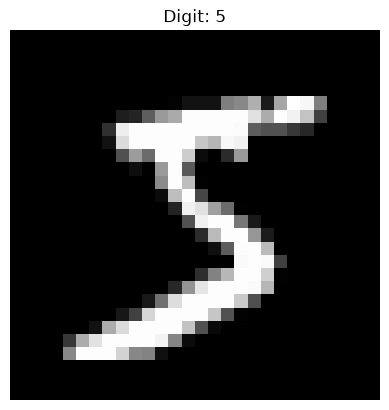

In [13]:

import struct
import numpy as np
import matplotlib.pyplot as plt


def load_mnist_images(path):
    with open(path, "rb") as f:
        # IDX3 header: magic number, image count, rows, columns
        magic, count, rows, cols = struct.unpack(">IIII", f.read(16))

        if magic != 2051:
            raise ValueError(f"Invalid image file: {path}")

        images = np.frombuffer(f.read(), dtype=np.uint8)
        images = images.reshape(count, rows, cols)

    return images


def load_mnist_labels(path):
    with open(path, "rb") as f:
        # IDX1 header: magic number, label count
        magic, count = struct.unpack(">II", f.read(8))

        if magic != 2049:
            raise ValueError(f"Invalid label file: {path}")

        labels = np.frombuffer(f.read(), dtype=np.uint8)

    if len(labels) != count:
        raise ValueError("Label count does not match the header")

    return labels


# Load the four files
x_train = load_mnist_images("train-images.idx3-ubyte")
y_train = load_mnist_labels("train-labels.idx1-ubyte")

x_test = load_mnist_images("t10k-images.idx3-ubyte")
y_test = load_mnist_labels("t10k-labels.idx1-ubyte")

# Normalize pixels from [0, 255] to [0, 1]
x_train = x_train.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

# Display a sample
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Digit: {y_train[0]}")
plt.axis("off")
plt.show()


In [2]:
from GDL_code_master.models.AE import Autoencoder

I0000 00:00:1792581945.002857   11114 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792581945.062038   11114 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792581946.293283   11114 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [ ]:
class autoencoder_model(tf.keras.Model):
    def __init__(self, n_conv_layer):
        self.n_conv_layer = n_conv_layer
        self.model = self.build_model(n_conv_layer)
    def build_model(self, n_conv_layer):
        #encoder 
  
        inputs = Input(shape=(28, 28, 1) , name='encoder_input' )
        x = inputs
        for i in range(n_conv_layer ):
            x =keras.layers.Conv2D(filters = 32,
                                    kernel_size=(3,3), 
                                    activation='relu', 
                                    padding='same',
                                    name = f'conv2d_{i}')(x)
        shape_before_flatten = keras.backend.int_shape(x)[1:]
        print(shape_before_flatten)

        x = keras.layers.Flatten()(x)
        
        
        z = keras.layers.Dense(2, name='latent_vector')(x)


        ## decoder 

        decoder_input = z
        x = keras.layers.Dense(int(np.prod(shape_before_flatten)))(decoder_input)
        x = keras.layers.Reshape(shape_before_flatten)(x)
        for i in range(n_conv_layer):
            x = keras.layers.Conv2DTranspose(filters = 32,
                                            kernel_size=(3,3), 
                                            activation='relu', 
                                            padding='same',
                                            name = f'deconv2d_{i}')(x)
        outputs = keras.layers.Conv2DTranspose(filters = 1,
                                            kernel_size=(3,3),
                                            activation='sigmoid',
                                            padding='same',
                                            name='decoder_output')(x)
        return Model(inputs=inputs, outputs=outputs, name='autoencoder')


In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models, Input, Model
import tensorflow.keras as keras 
from tensorflow.keras import backend , layers 
import pandas as pd 

I0000 00:00:1792686608.844886   43049 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792686609.005636   43049 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792686611.125431   43049 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [5]:

def autoencoder_model(n_conv_layer):
    inputs = Input(shape=(28, 28, 1), name="encoder_input")
    x = inputs

    for i in range(n_conv_layer):
        x = keras.layers.Conv2D(
            filters=32,
            kernel_size=(3, 3),
            activation="relu",
            padding="same",
            name=f"conv2d_{i}"
        )(x)

    shape_before_flatten = keras.backend.int_shape(x)[1:]

    x = keras.layers.Flatten()(x)
    z = keras.layers.Dense(2, name="latent_vector")(x)

    # Decoder starts directly from z
    x = keras.layers.Dense(
        int(np.prod(shape_before_flatten))
    )(z)

    x = keras.layers.Reshape(shape_before_flatten)(x)

    for i in range(n_conv_layer):
        x = keras.layers.Conv2DTranspose(
            filters=32,
            kernel_size=(3, 3),
            activation="relu",
            padding="same",
            name=f"deconv2d_{i}"
        )(x)

    outputs = keras.layers.Conv2DTranspose(
        filters=1,
        kernel_size=(3, 3),
        activation="sigmoid",
        padding="same",
        name="decoder_output"
    )(x)

    return Model(inputs=inputs, outputs=outputs, name="autoencoder")


model = autoencoder_model(3)

model.compile(
    optimizer=keras.optimizers.Adam(),
    loss=rms_pixel_error
)

model.summary()



Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_0 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 2)              │        50,178 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25088)          │        75,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ deconv2d_0 (Conv2DTranspose)    │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ deconv2d_1 (Conv2DTranspose)    │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ deconv2d_2 (Conv2DTranspose)    │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output                  │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 172,291 (673.01 KB)

 Trainable params: 172,291 (673.01 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
def rms_pixel_error(y_true, y_pred):
    return tf.sqrt(tf.reduce_mean(tf.square(y_true - y_pred)))
model = autoencoder_model(3)
model.compile(optimizer='adam', loss=rms_pixel_error, metrics=['accuracy'])


In [6]:
history = model.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=128,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/20


I0000 00:00:1792686674.164184   43362 service.cc:153] XLA service 0x755ac4039fe0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792686674.164243   43362 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.22.0)
I0000 00:00:1792686674.227213   43362 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792686674.806517   43362 cuda_dnn.cc:461] Loaded cuDNN version 92200
I0000 00:00:1792686674.827283   43362 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3542__.11


  3/422 ━━━━━━━━━━━━━━━━━━━━ 19s 46ms/step - loss: 0.4798   

I0000 00:00:1792686682.446715   43362 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


419/422 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.2735

I0000 00:00:1792686691.117103   43362 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3542__.11
I0000 00:00:1792686693.074857   43879 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 8 bytes spill stores, 8 bytes spill loads



422/422 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - loss: 0.2443 - val_loss: 0.2206
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2176 - val_loss: 0.2111
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2118 - val_loss: 0.2087
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2088 - val_loss: 0.2050
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2068 - val_loss: 0.2042
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2054 - val_loss: 0.2023
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - loss: 0.2045 - val_loss: 0.2013
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - loss: 0.2033 - val_loss: 0.2007
Epoch 9/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - loss: 0.2027 - val_loss: 0.2005
Epoch 10/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2020 - val_loss: 0.1998
Epoch 11/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - loss: 0.2014 - val_loss: 0.1997
Epoch 12/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/st

In [79]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=rms_pixel_error
)

In [80]:
print(x_train.shape)
print(x_train.dtype)
print(x_train.min(), x_train.max())

(60000, 28, 28)
float32
0.0 1.0


In [81]:
x_train = x_train[..., None]
x_test = x_test[..., None]

print(x_train.shape)
# (60000, 28, 28, 1)

(60000, 28, 28, 1)


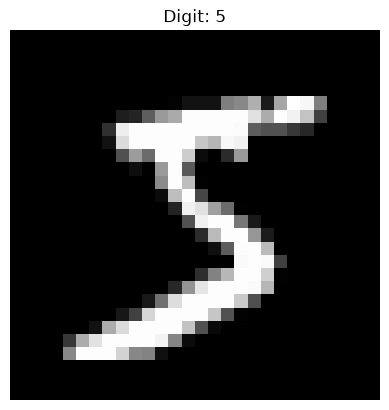

In [7]:
# Display a sample
plt.imshow(x_train[0], cmap="gray")
plt.title(f"Digit: {y_train[0]}")
plt.axis("off")
plt.show()


In [8]:
y_pred = model.predict(x_test[0:1])# BATCH DIMANSSION SHOULD NOT BE REMOVED, OTHERWISE IT WILL THROW ERROR

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


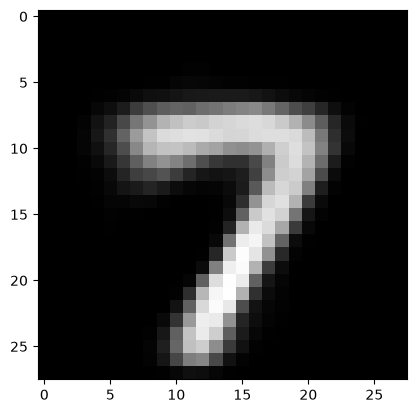

In [10]:
plt.imshow(y_pred[0], cmap="gray")

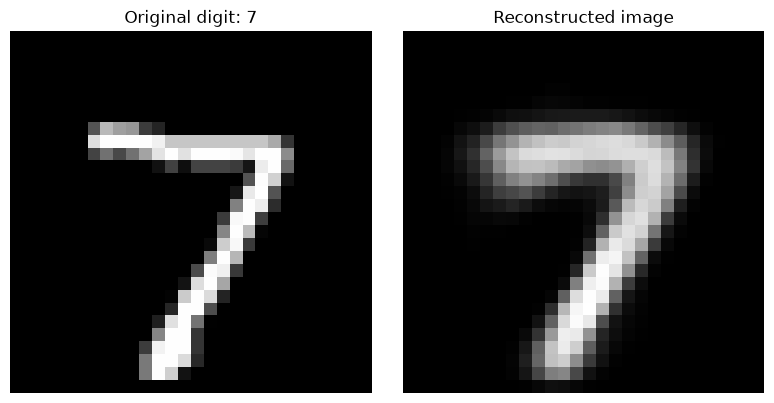

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample[0, :, :, 0], cmap="gray")
plt.title(f"Original digit: {y_test[0]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(prediction[0, :, :, 0], cmap="gray")
plt.title("Reconstructed image")
plt.axis("off")

plt.tight_layout()
plt.show()

# varational autoencoder 

In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models, Input, Model
import tensorflow.keras as keras 
from tensorflow.keras import backend , layers 
import pandas as pd 
import numpy as np

I0000 00:00:1792698339.986803   55775 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792698340.123254   55775 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792698341.945552   55775 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [5]:
def rms_pixel_error(y_true, y_pred):
    return tf.sqrt(tf.reduce_mean(tf.square(y_true - y_pred)))


In [5]:
import gc
import tensorflow as tf
from tensorflow.keras import backend as K

# Clear Keras global state
K.clear_session()

# Ask Python to release unused objects
gc.collect()

0

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Input, Dense, Flatten, Reshape 
from tensorflow.keras.models import Model
import numpy as np


class Sampling(keras.layers.Layer):
    def call(self, inputs):
        mu, log_var = inputs

        epsilon = tf.random.normal(
            shape=tf.shape(mu)
        )

        z = mu + tf.exp(0.5 * log_var) * epsilon

        kl_loss = -0.5 * tf.reduce_sum(
            1 + log_var - tf.square(mu) - tf.exp(log_var),
            axis=1
        )

        self.add_loss(tf.reduce_mean(kl_loss))

        return z

In [34]:

def autoencoder_model(n_conv_layer, z_dim=2):

    # ---------------- Encoder ----------------
    inputs = Input(
        shape=(64, 64, 1),
        name="encoder_input"
    )

    x = inputs

    for i in range(n_conv_layer):
        x = keras.layers.Conv2D(
            filters=32,
            kernel_size=(3, 3),
            padding="same",
            name=f"conv2d_{i}"
        )(x)
        
        x = keras.layers.BatchNormalization(name=f"bn_{i}")(x)
        x = keras.layers.Activation("leaky_relu", name=f"act_{i}")(x)
        x = keras.layers.Dropout(0.2, name=f"dropout_{i}")(x)

    shape_before_flatten = keras.backend.int_shape(x)[1:]

    x = Flatten(name="flatten")(x)

    # Distribution parameters: branch from encoder features
    mu = Dense(z_dim, name="latent_mean")(x)
    log_var = Dense(z_dim, name="latent_log_var")(x)

    # Sample the latent vector and register KL loss
    z = Sampling(name="sampling")([mu, log_var])

    # ---------------- Decoder ----------------
    x = Dense(
        int(np.prod(shape_before_flatten)),
        activation="relu",
        name="decoder_dense"
    )(z)

    x = Reshape(
        shape_before_flatten,
        name="decoder_reshape"
    )(x)

    for i in range(n_conv_layer):
        x = keras.layers.Conv2DTranspose(
            filters=32,
            kernel_size=(3, 3),
            padding="same",
            name=f"deconv2d_{i}"
        )(x)
        x = keras.layers.BatchNormalization(name=f"bn_dec_{i}")(x)
        x = keras.layers.Activation("leaky_relu", name=f"act_dec_{i}")(x)
        x = keras.layers.Dropout(0.2, name=f"dropout_dec_{i}")(x)

    outputs = keras.layers.Conv2DTranspose(
        filters=1,
        kernel_size=(3, 3),
        activation="sigmoid",
        padding="same",
        name="decoder_output"
    )(x)

    return Model(
        inputs=inputs,
        outputs=outputs,
        name="vae"
    )


In [32]:
def rms_pixel_error(y_true, y_pred):
    return tf.sqrt(
        tf.reduce_mean(tf.square(y_true - y_pred))
    )


model = autoencoder_model(n_conv_layer=3, z_dim=2)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=rms_pixel_error
)

model.summary()

Model: "vae"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_0 (Conv2D)   │ (None, 64, 64,    │        320 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_0                │ (None, 64, 64,    │        128 │ conv2d_0[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ act_0 (Activation)  │ (None, 64, 64,    │          0 │ bn_0[0][0]        │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_0 (Dropout) │ (None, 64, 64,    │          0 │ act_0[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      9,248 │ dropout_0[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_1                │ (None, 64, 64,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ act_1 (Activation)  │ (None, 64, 64,    │          0 │ bn_1[0][0]        │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 64,    │          0 │ act_1[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │      9,248 │ dropout_1[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_2                │ (None, 64, 64,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ act_2 (Activation)  │ (None, 64, 64,    │          0 │ bn_2[0][0]        │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64, 64,    │          0 │ act_2[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 131072)    │          0 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent_mean (Dense) │ (None, 2)         │    262,146 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent_log_var      │ (None, 2)         │    262,146 │ flatten[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ latent_mean[0][0… │
│                     │                   │            │ latent_log_var[0… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 965,125 (3.68 MB)

 Trainable params: 964,741 (3.68 MB)

 Non-trainable params: 384 (1.50 KB)

In [14]:
history = model.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=128,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/20


I0000 00:00:1792698505.749131   56690 service.cc:153] XLA service 0x766aa404e410 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792698505.749228   56690 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.22.0)
I0000 00:00:1792698505.834689   56690 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792698506.519673   56690 cuda_dnn.cc:461] Loaded cuDNN version 92200
I0000 00:00:1792698506.558004   56690 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3760__.15


  1/422 ━━━━━━━━━━━━━━━━━━━━ 1:33:31 13s/step - loss: 0.4855

I0000 00:00:1792698515.773703   56690 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


421/422 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.2919

I0000 00:00:1792698524.830667   56691 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3760__.15
I0000 00:00:1792698526.917578   57538 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_18', 8 bytes spill stores, 8 bytes spill loads



422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.2919

I0000 00:00:1792698532.527575   56691 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5439__.5
I0000 00:00:1792698534.324834   56688 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5439__.5


422/422 ━━━━━━━━━━━━━━━━━━━━ 33s 47ms/step - loss: 0.2675 - val_loss: 0.2588
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - loss: 0.2596 - val_loss: 0.2589
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.2595 - val_loss: 0.2587
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - loss: 0.2595 - val_loss: 0.2587
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.2595 - val_loss: 0.2586
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.2595 - val_loss: 0.2586
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.2595 - val_loss: 0.2586
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.2595 - val_loss: 0.2587
Epoch 9/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.2595 - val_loss: 0.2587
Epoch 10/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.2595 - val_loss: 0.2587
Epoch 11/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.2595 - val_loss: 0.2587
Epoch 12/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/st

In [15]:
y_pred = model.predict(x_test[0:1])  # BATCH DIMENSION SHOULD NOT BE REMOVED, OTHERWISE IT WILL THROW ERROR

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


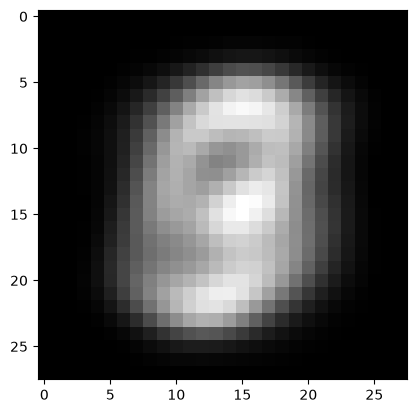

In [19]:
plt.imshow(y_pred[0], cmap="gray")

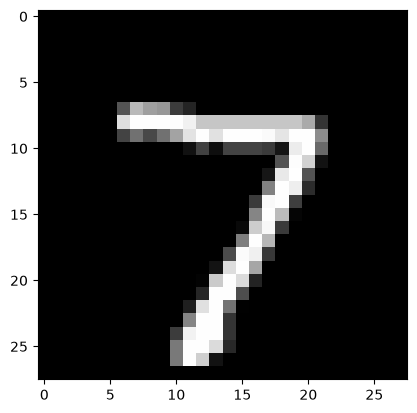

In [17]:
plt.imshow(x_test[0], cmap="gray")

In [78]:
import tensorflow as tf

_, height, width, channels = model.input_shape

print("Required image size:", height, width, channels)

def load_image(path):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_jpeg(
        image_bytes,
        channels=channels
    )

    image = tf.image.resize(
        image,
        [height, width]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image

dataset = tf.data.Dataset.from_tensor_slices(image_paths)

dataset = dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

dataset = dataset.batch(32).prefetch(tf.data.AUTOTUNE)

train_dataset = dataset.map(lambda images: (images, images))

Required image size: 64 64 3


In [79]:
class Sampling(keras.layers.Layer):
    def call(self, inputs):
        mu, log_var = inputs

        # Prevent numerical overflow in the variance calculation
        log_var = tf.clip_by_value(log_var, -10.0, 10.0)

        epsilon = tf.random.normal(shape=tf.shape(mu))

        z = mu + tf.exp(0.5 * log_var) * epsilon

        kl_loss = -0.5 * tf.reduce_sum(
            1.0 + log_var
            - tf.square(mu)
            - tf.exp(log_var),
            axis=1
        )

        self.add_loss(tf.reduce_mean(kl_loss))

        return z

In [80]:

def autoencoder_model(n_conv_layer, z_dim=200):

    # ---------------- Encoder ----------------
    inputs = Input(
        shape=(64, 64, 3),
        name="encoder_input"
    )

    x = inputs

    for i in range(n_conv_layer):
        x = keras.layers.Conv2D(
            filters=32,
            kernel_size=(3, 3),
            padding="same",
            name=f"conv2d_{i}"
        )(x)
        
        x = keras.layers.BatchNormalization(name=f"bn_{i}")(x)
        x = keras.layers.Activation("leaky_relu", name=f"act_{i}")(x)
        x = keras.layers.Dropout(0.2, name=f"dropout_{i}")(x)

    shape_before_flatten = keras.backend.int_shape(x)[1:]

    x = Flatten(name="flatten")(x)

    # Distribution parameters: branch from encoder features
    mu = Dense(z_dim, name="latent_mean")(x)
    log_var = Dense(z_dim, name="latent_log_var")(x)

    # Sample the latent vector and register KL loss
    z = Sampling(name="sampling")([mu, log_var])

    # ---------------- Decoder ----------------
    x = Dense(
        int(np.prod(shape_before_flatten)),
        activation="relu",
        name="decoder_dense"
    )(z)

    x = Reshape(
        shape_before_flatten,
        name="decoder_reshape"
    )(x)

    for i in range(n_conv_layer):
        x = keras.layers.Conv2DTranspose(
            filters=32,
            kernel_size=(3, 3),
            padding="same",
            name=f"deconv2d_{i}"
        )(x)
        x = keras.layers.BatchNormalization(name=f"bn_dec_{i}")(x)
        x = keras.layers.Activation("leaky_relu", name=f"act_dec_{i}")(x)
        x = keras.layers.Dropout(0.2, name=f"dropout_dec_{i}")(x)

    outputs = keras.layers.Conv2DTranspose(
        filters=3,
        kernel_size=(3, 3),
        activation="sigmoid",
        padding="same",
        name="decoder_output"
    )(x)

    return Model(
        inputs=inputs,
        outputs=outputs,
        name="vae"
    )


In [72]:
def rms_pixel_error(y_true, y_pred):
    return tf.sqrt(
        tf.reduce_mean(tf.square(y_true - y_pred))
    )

model = autoencoder_model(n_conv_layer=4, z_dim=200)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=rms_pixel_error
)

model.summary()

Model: "vae"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_0 (Conv2D)   │ (None, 64, 64,    │        896 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_0                │ (None, 64, 64,    │        128 │ conv2d_0[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ act_0 (Activation)  │ (None, 64, 64,    │          0 │ bn_0[0][0]        │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_0 (Dropout) │ (None, 64, 64,    │          0 │ act_0[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      9,248 │ dropout_0[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_1                │ (None, 64, 64,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ act_1 (Activation)  │ (None, 64, 64,    │          0 │ bn_1[0][0]        │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 64,    │          0 │ act_1[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │      9,248 │ dropout_1[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_2                │ (None, 64, 64,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ act_2 (Activation)  │ (None, 64, 64,    │          0 │ bn_2[0][0]        │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64, 64,    │          0 │ act_2[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │      9,248 │ dropout_2[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_3                │ (None, 64, 64,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ act_3 (Activation)  │ (None, 64, 64,    │          0 │ bn_3[0][0]        │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64, 64,    │          0 │ act_3[0][0]     

 Total params: 78,841,617 (300.76 MB)

 Trainable params: 78,841,105 (300.75 MB)

 Non-trainable params: 512 (2.00 KB)

In [81]:
for x, y in train_dataset.take(1):
    print("Input shape:", x.shape)
    print("Target shape:", y.shape)
    print("Data type:", x.dtype)
    print("Pixel range:",
          tf.reduce_min(x).numpy(),
          tf.reduce_max(x).numpy())

Input shape: (32, 64, 64, 3)
Target shape: (32, 64, 64, 3)
Data type: <dtype: 'float32'>
Pixel range: 0.0 1.0


In [82]:
callbacks = [
    keras.callbacks.TerminateOnNaN()
]

history = model.fit(
    train_dataset,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10


ValueError: Creating variables on a non-first call to a function decorated with tf.function.

In [26]:
print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

for x, y in train_dataset.take(1):
    print("Dataset input shape:", x.shape)
    print("Dataset target shape:", y.shape)

Model input shape: (None, 64, 64, 1)
Model output shape: (None, 64, 64, 1)
Dataset input shape: (32, 64, 64, 3)
Dataset target shape: (32, 64, 64, 3)


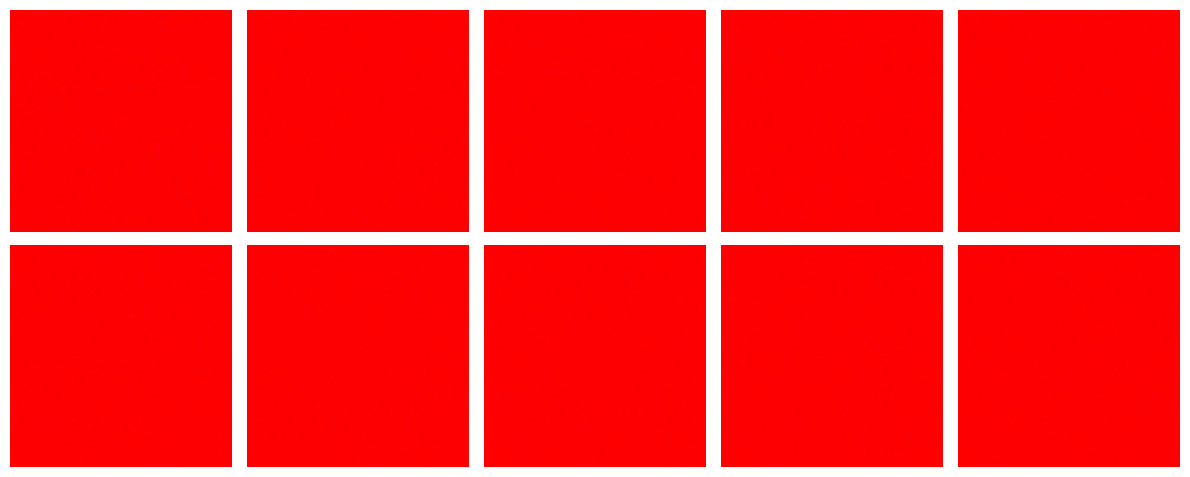

In [76]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras

z_dim = 200

# Build a decoder using the trained model's existing layers
latent_input = keras.Input(shape=(z_dim,), name="z_input")

x = model.get_layer("decoder_dense")(latent_input)
x = model.get_layer("decoder_reshape")(x)

for i in range(3):
    x = model.get_layer(f"deconv2d_{i}")(x)
    x = model.get_layer(f"bn_dec_{i}")(x)
    x = model.get_layer(f"act_dec_{i}")(x)
    x = model.get_layer(f"dropout_dec_{i}")(x)

output = model.get_layer("decoder_output")(x)

decoder = keras.Model(latent_input, output, name="decoder")

# Sample 10 latent vectors from the standard normal prior
z_random = tf.random.normal((10, z_dim))

# Generate faces
generated_faces = decoder.predict(z_random, verbose=0)

# Display
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_faces[i, :, :, 0], cmap="brg", vmin=0, vmax=1)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [83]:
train_dataset = dataset.map(lambda images: (images, images))

model = autoencoder_model(n_conv_layer=3, z_dim=200)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=rms_pixel_error
)

history = model.fit(
    train_dataset,
    epochs=10
)

Epoch 1/10
628/628 ━━━━━━━━━━━━━━━━━━━━ 57s 68ms/step - loss: 62.7038
Epoch 2/10
628/628 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - loss: 114.8062
Epoch 3/10
628/628 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - loss: 330.2943
Epoch 4/10
628/628 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - loss: 199.4312
Epoch 5/10
628/628 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - loss: 187.4971
Epoch 6/10
628/628 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - loss: 133.3429
Epoch 7/10
628/628 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - loss: 129.7006
Epoch 8/10
628/628 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - loss: 119.6725
Epoch 9/10
628/628 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - loss: 125.8401
Epoch 10/10
628/628 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - loss: 134.5141


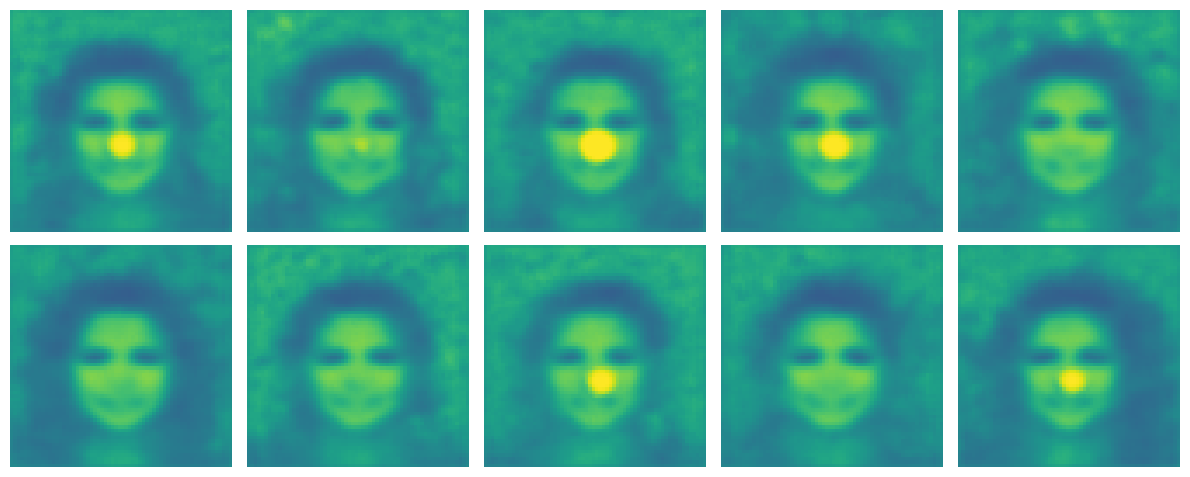

In [86]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras

z_dim = 200

# Build a decoder using the trained model's existing layers
latent_input = keras.Input(shape=(z_dim,), name="z_input")

x = model.get_layer("decoder_dense")(latent_input)
x = model.get_layer("decoder_reshape")(x)

for i in range(3):
    x = model.get_layer(f"deconv2d_{i}")(x)
    x = model.get_layer(f"bn_dec_{i}")(x)
    x = model.get_layer(f"act_dec_{i}")(x)
    x = model.get_layer(f"dropout_dec_{i}")(x)

output = model.get_layer("decoder_output")(x)

decoder = keras.Model(latent_input, output, name="decoder")

# Sample 10 latent vectors from the standard normal prior
z_random = tf.random.normal((10, z_dim))

# Generate faces
generated_faces = decoder.predict(z_random, verbose=0)

# Display
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_faces[i, :, :, 0], vmin=0, vmax=1)
    ax.axis("off")

plt.tight_layout()
plt.show()

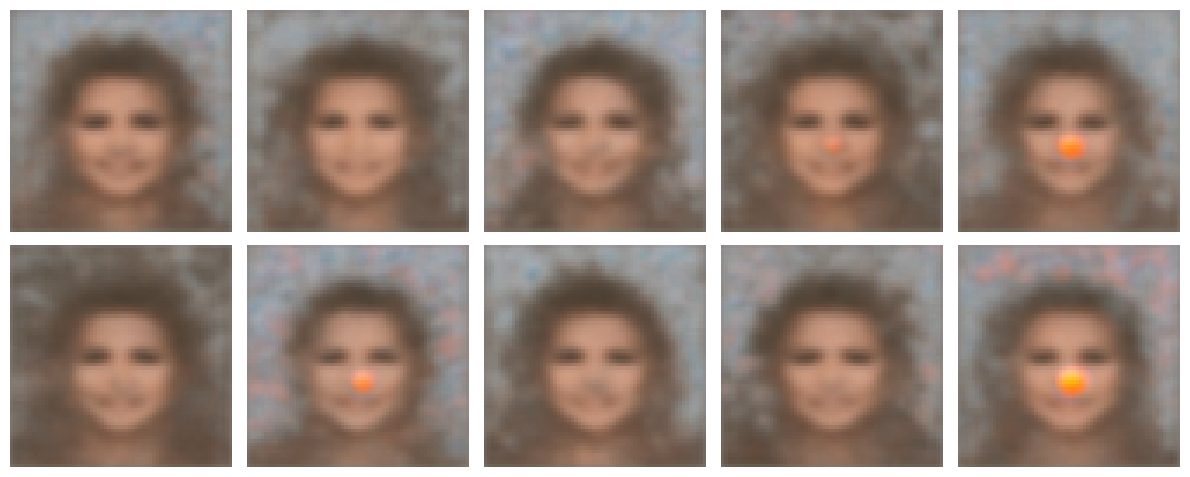

In [87]:
z_random = tf.random.normal((10, 200))
generated_faces = decoder.predict(z_random, verbose=0)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_faces[i])  # RGB: no cmap="gray"
    ax.axis("off")

plt.tight_layout()
plt.show()